**&copy; CentraleSupélec.  
For any question, contact the author at frederic.pennerath@centralesupelec.fr**

<h1>
<font size="30">Statistical modelling</font>
for diabetes type II diagnosis
</h1>


This labwork is about **statistical analysis** of a dataset and **statical modelling** of the underlying problem.
Its main objectives are:

- To show you why looking at the data using tools of **descriptive statistics**, like the *statistical visualization toolbox* **Seaborn**, is essential 1) to detect anomalies or specificities before being able to properly process these data, and 2) to guide you in formulating appropriate modelling hypothesis (e.g. shape of distributions, structure of Bayesian network, etc).
- To put into practice the **Gaussian Discriminant Analysis** (LDA & QDA) introduced during the lectures.
- Few other more secondary aspects, like **imputation of missing values**, **data transformation**, etc.

The chosen dataset is the well-known [Pima Indians diabetes dataset](https://www.kaggle.com/uciml/pima-indians-diabetes-database) already introduced during the tutorial (aka TD). It describes few hundreds of Pima indian women that have been tested for diabetes of type II (priorly called *non-insulin dependent diabetes mellitus*) as this population is particularly affected by this disease. Every individual is described by eight descriptive features along with a target variable indicating whether she will eventually suffer from diabetes type II within 5 years.

Here our purpose is not simply to make prediction and to optimize, as with a classical black-box ML approach.
The objective is to get interpretable insights to provide clues about the generative process underlying the data.
This can be useful for experts (here medical doctors) to validate their knowledge about diabetes, to formulate new hypothesis, to postulate causality relationships, etc.

When considering a dataset, it is essential to collect pieces of information about the origin of the dataset, the topics to which the data are linked, the precise meaning of features, etc. Here, the chosen dataset was initially built in the eighties to design a new diagnosis tool for diabetes, based on neural networks.
All details are given in the article:

*Smith, J.W., Everhart, J.E., Dickson, W.C., Knowler, W.C., & Johannes, R.S. (1988). Using the ADAP learning algorithm to forecast the onset of diabetes mellitus. In Proceedings of the Symposium on Computer Applications and Medical Care (pp. 261--265). IEEE Computer Society Press.*

The article contains in particular the meaning of the dataset features (see provided file ```article.pdf```). A summary of precise definitions for all features has already been provided during the tutorial.

Although very classical, this data set is interesting to illustrate the task of statistical modelling, as :
- Features have clear and different meaning.
- Prior knowledge exists in medical literature giving insights about causality and dependence strengths between variables.
- As some data features (e.g insulin rate) are costly to acquire, the number of available samples are limited and inaccurate so that a large amount of residual uncertainty in the predictions remains whatever the method or model used.

Let's start by preloading the basic toolkit.

In [2]:
import numpy as np
import matplotlib.pyplot as plt   
import pandas as pd
import seaborn as sns

In [3]:
# Default settings for matplotlib
%matplotlib inline
plt.rcParams['figure.figsize'] = [12, 8] # Change these dimensions to match your screen size

 # Data preprocessing
 
 ## Data loading
 
**Question:**  
First check the format of the dataset file ``diabetes.csv`` by looking at its content (using for instance the UNIX shell command ``head``).

In [4]:
!powershell -command "Get-Content diabetes.csv -TotalCount 10"


Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
6,148,72,35,0,33.6,0.627,50,1
1,85,66,29,0,26.6,0.351,31,0
8,183,64,0,0,23.3,0.672,32,1
1,89,66,23,94,28.1,0.167,21,0
0,137,40,35,168,43.1,2.288,33,1
5,116,74,0,0,25.6,0.201,30,0
3,78,50,32,88,31,0.248,26,1
10,115,0,0,0,35.3,0.134,29,0
2,197,70,45,543,30.5,0.158,53,1


This is a very common and standard file format called **CSV** for *Comma Separated Value*, where fields/features are separed by commas. The first row provides the field names whereas every subsequent line provides the respective field values of a new sample. As a consequence, the number of samples is $l-1$ where $l$ is the number of lines in the dataset.

**Question:**  
Check very simply how many samples are provided (using for instance the UNIX shell command ``wc -l``).

In [5]:
!powershell -command "Get-Content diabetes.csv | Measure-Object -Line"


Lines Words Characters Property
----- ----- ---------- --------
  769                          





**Question:**  
Load the CSV file into a Pandas dataframe (you can use Pandas function ``read_csv``). Check the content of the dataframe (using the ``head()`` method).

In [6]:
df = pd.read_csv("diabetes.csv")
df.head

<bound method NDFrame.head of      Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0              6      148             72             35        0  33.6   
1              1       85             66             29        0  26.6   
2              8      183             64              0        0  23.3   
3              1       89             66             23       94  28.1   
4              0      137             40             35      168  43.1   
..           ...      ...            ...            ...      ...   ...   
763           10      101             76             48      180  32.9   
764            2      122             70             27        0  36.8   
765            5      121             72             23      112  26.2   
766            1      126             60              0        0  30.1   
767            1       93             70             31        0  30.4   

     DiabetesPedigreeFunction  Age  Outcome  
0                       0.627   50 

## Data cleansing

Some features have long names. For sake of clarity and conciseness, I advise you to use shorter names like
* ``Pressure`` for the blood pressure
* ``Skin`` for the skin thickness
* ``Pedigree`` for the pedigree influence score
* ``Diabetes`` for the target variable

**Question:**  
Rename the respective features accordingly, using the dataframe method ``rename()``.

**Reminder:** *to get some help about how to use a function or a method you should use ``help(<the function>)`` or ``<the function> ?`` (or ``help(<the object or class>.<the method name>)`` in case of a method).*

In [7]:
df.rename(columns={"BloodPressure":"Pressure", "SkinThickness": "Skin", "DiabetesPedigreeFunction": "Pedigree", "Outcome": "Diabetes"}, inplace=True)

### Column formats

So far so good. Another thing we must check is the type used to encode values for each column of the dataframe. The type of column (also called a *Pandas series*) is specified by a column field called ``dtype``. The main supported types are ``int64``, ``float64``, ``bool``, ``datetime64`` (to encode dates), ``object`` (including strings) and ``category`` (i.e a finite list of symbols).
The type of a column is automatically inferred by Pandas when parsing the field values in the CSV file (e.g. integral numbers are mapped to type ``int64``, decimal numbers to ``float64``, etc).

**Question:**  
Check the types of every feature, thanks to the dataframe method ``info()``. Compare to the expected types.

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Pregnancies  768 non-null    int64  
 1   Glucose      768 non-null    int64  
 2   Pressure     768 non-null    int64  
 3   Skin         768 non-null    int64  
 4   Insulin      768 non-null    int64  
 5   BMI          768 non-null    float64
 6   Pedigree     768 non-null    float64
 7   Age          768 non-null    int64  
 8   Diabetes     768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


The expected types are integer for variable `Pregnancies`, categorical for `Diabetes` and float for all remaining attributes. It is important that the `Diabetes` variable be considered as categorical and not numerical, otherwise *scikit-learn* will consider the current problem as a regression problem, not as a classification problem.

**Question:**  
Convert the series to their expected types using the dataframe method `astype()`.
Then rename possible categories into `no` and `yes` (instead of 0 and 1) using the series method `cat.rename_categories()`. Check the result.

In [9]:
df = df.astype({
    'Pregnancies': 'int64',
    'Glucose': 'float64',
    'Pressure': 'float64',
    'Skin': 'float64',
    'Insulin': 'float64',
    'BMI':'float64',
    'Pedigree': 'float64',
    'Age': 'float64',
    'Diabetes': 'category'
})

df["Diabetes"] = df['Diabetes'].cat.rename_categories({0: "no", 1: "yes"})
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   Pregnancies  768 non-null    int64   
 1   Glucose      768 non-null    float64 
 2   Pressure     768 non-null    float64 
 3   Skin         768 non-null    float64 
 4   Insulin      768 non-null    float64 
 5   BMI          768 non-null    float64 
 6   Pedigree     768 non-null    float64 
 7   Age          768 non-null    float64 
 8   Diabetes     768 non-null    category
dtypes: category(1), float64(7), int64(1)
memory usage: 48.9 KB


In [10]:
df.head()

,Pregnancies,Glucose,Pressure,Skin,Insulin,BMI,Pedigree,Age,Diabetes
0,6,148.0,72.0,35.0,0.0,33.6,0.627,50.0,yes
1,1,85.0,66.0,29.0,0.0,26.6,0.351,31.0,no
2,8,183.0,64.0,0.0,0.0,23.3,0.672,32.0,yes
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21.0,no
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33.0,yes


# Two options: be a pro or an amateur.

From here, you have two options to tackle the problem. Either you choose the amateur fast track or you take the longer professional path. 

## The amateur fast track

Let's start with the amateur fast track. 

What an amateur will do after loading the data is to cross-validate right away many available ML methods one after the other, sometimes using grid search to tune some hyper-parameters. On standard problems, the best results will typically be obtained by random forests or boosting algorithms, using efficient implementations like `XGBoost` or `LighGBM` or with some neural networks, depending on the nature of the problem. This will give some good accuracy scores which the author will be quick to point out.

So let's try this.

First we need to feed the *scikit-learn* algorithms with 
- a 2D numpy array $X$ containing the input features as columns
- a 1D numpy vector $y$ containing the output to predict

**Question:**  
Extract $X$ and $y$ from the dataframe (we will use all available features)

In [11]:
features = list(df.columns)
features.remove('Diabetes')

X = df.loc[:, features]
y = df['Diabetes'].cat.codes

print('X shape:', X.shape)
print('y shape:', y.shape)

X shape: (768, 8)
y shape: (768,)


To ease method comparison, we provide a score board that cross-validates methods and store results in dataframe.

In [12]:
from sklearn.model_selection import cross_validate

class ScoreBoard:
    '''
    Scoreboard that evaluates different methods for a given experiment and collect
    evaluation scores into a Pandas dataframe.
    '''
    def __init__(self, scoring_functions={'acc' : 'accuracy', 'auc': 'roc_auc', 'logL': 'neg_log_loss'}, n_folds=10):
        '''
        Constructor
        
        - scoring_functions: dict of scoring functions (name mapped to a scoring function or scikit score name)
        - n_folds: default number of folds for cross-validation
        '''
        self.scoring_functions = scoring_functions
        self.score_names = list(scoring_functions.keys())
        self.scores = None
        self.n_folds = n_folds
        
    def _repr_html_(self):
        '''
        Convert object to an HTML representation (called by Jupyter notebook)
        '''
        if self.scores is not None:
            return self.scores._repr_html_()
        else:
            return "No scores available"
    
    def test(self, name, clf, X, Y, n_folds=None):
        '''
        Cross-validate a classifier
        '''
        if n_folds is None:
            n_folds = self.n_folds
        res  = cross_validate(clf, X, Y, cv=self.n_folds, scoring=self.scoring_functions, error_score='raise')

        entry = { score_name: np.mean(res[f'test_{score_name}']) for score_name in self.score_names }
        entry['classifier'] = name
        self.scores = pd.concat([self.scores, pd.DataFrame([entry], columns= [ 'classifier' ] + self.score_names)], ignore_index=True)


**Question:**  
Look at and run the code below that compare few on-the-shelf methods provided by *scikit-learn*.

In [13]:
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

clfs = { 
    'NaiveBayes': GaussianNB(),
    'LogReg': LogisticRegression(max_iter=1000),
    'RandomForest': RandomForestClassifier(max_depth=10)
}

scores = ScoreBoard()

for name,clf in clfs.items():
    scores.test(name, clf, X, y)
scores

,classifier,acc,auc,logL
0,NaiveBayes,0.756494,0.815991,-0.620058
1,LogReg,0.773479,0.829419,-0.484010
2,RandomForest,0.768233,0.828407,-0.481698


An AUC of almost 0.83 is pretty cool!!

**Question:**  
Are you happy with this? Hope the answer is no.

### What's the problem with this approach?

Well... There was no reflection from start to finish. In particular none of the following questions has been answered:
- Have the data been correctly preprocessed? Did I introduced some bias into the predictor?
- What did I learn about the problem? Was I curious about it? What can I say but my accuracy is 0.77? Can I be proud of what I did (mostly copy & paste one of the many similar Python scripts found on *kaggle.com*)?
- Can I trust my models? Would I feel comfortable to transfer these models to my customers?

Answers to these questions are actually all negative.

## A little bit of seriousness: back on the pro track

As we will see, the data have not been correctly preprocessed and the previous results are meaningless.

### Analyzing feature distributions

Let's do some sanity checks about how features are distributed.

**Question:**  
Use the dataframe `describe()` method to get the main characteristics (quantiles, etc) of numerical features. 
If you look carefully, you should already notice something weird.

In [14]:
df.describe()

,Pregnancies,Glucose,Pressure,Skin,Insulin,BMI,Pedigree,Age
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000


Glucose, pressure, skin, insulin, BMI have a minimum value of 0. This is not physically possible.
The 0 value must encode something special, likely a missing value.

Let's verify this hypothesis by looking at the distribution of features.
Python library `Seaborn` provides useful statistical plots.
In order to save you time, function `plot_marginal_dist` is provided below. It plots Seaborn histograms `histplot` of all features of a dataframe (and smoothed density for continuous variables). Passing the name of categorical feature to the `hue` argument allows to plot with different colors the distributions for every category.

**Question:**  
Apply this function to your dataframe. Observe the results and identify which variables are likely to have missing values. Is it consistent with what you know about the problem?

In [15]:
def plot_marginal_dist(df, features=None, hue=None, n_cols=2):
    '''
    Plot marginal distributions of a list of features
    
    - df is a Pandas dataframe
    - features is the list of feature names to plot. If set to None, all features are displayed.
    - hue is the name of a categorical feature. If set, every marginal distribution is split into
    multiple distributions of different colors, one per category of the hue variable.
    - n_cols is the number of columns of the plot grid.
    '''
    
    # If features is not provided, take all features by default
    if features is None:
        features = df.columns
        
    # Create a figure to host a grid of subplots
    plt.figure(tight_layout=True, frameon=False)

    # Number of grid rows
    n_rows = int(np.ceil(len(features) / n_cols))
    
    # For every feature
    for i, feature in enumerate(features, start=1):
        # Create a new subplot for each feature
        plt.subplot(n_rows, n_cols, i)
        
        # Plot parameters must differ whether the variable is categorial or numerical
        if df[feature].dtype.name == 'category':
            discrete, kde, stat = True, False, 'count' 
        else:
            discrete, kde, stat = False, True, 'density'
           
        # Here we call the Seaborn's histplot function to draw an histogram
        sns.histplot(data=df, x=feature, kde=kde, stat=stat, discrete=discrete, hue=hue, common_norm=False)

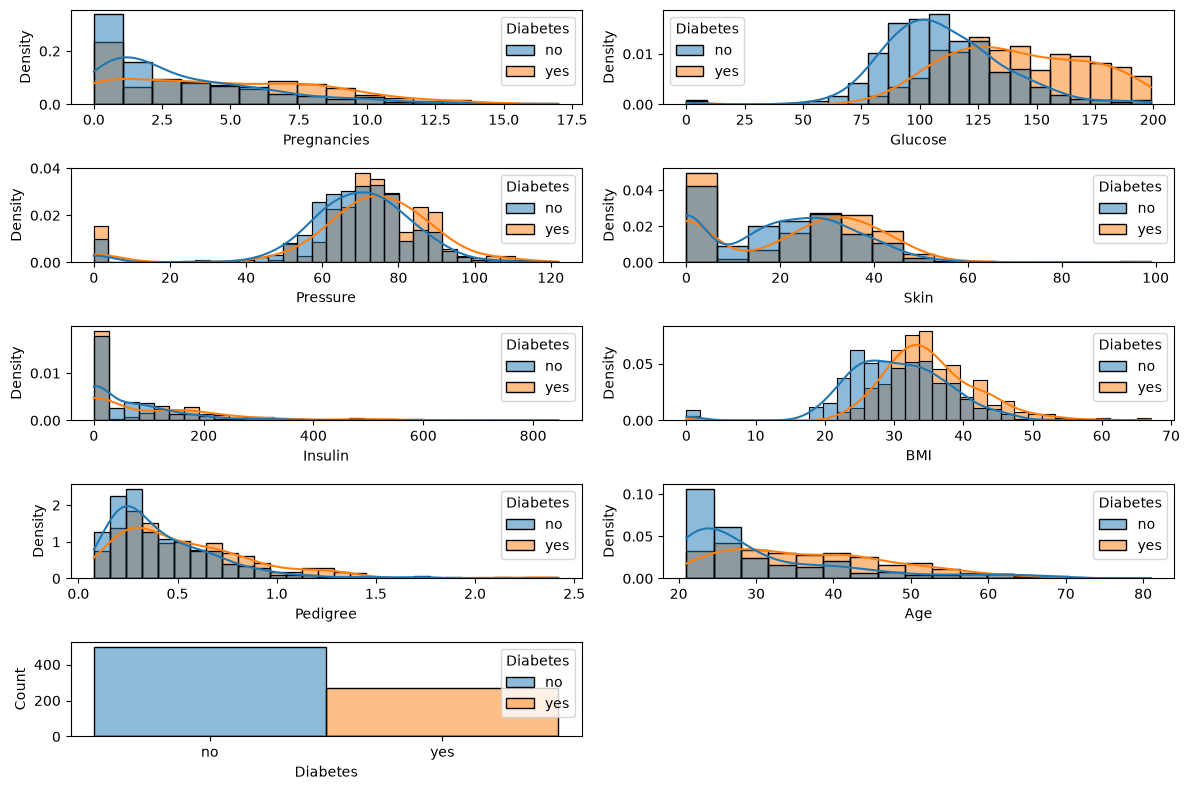

In [16]:
plot_marginal_dist(df, hue="Diabetes")

One observes abnormal peaks at zero in the distributions of variables `Glucose`, `Pressure`, `Skin`, `Insulin` and `BMI`. 

The reason is that some feature values are more difficult to collect than others as their measure is costly, requires more equipment, can be refused by the patient, can be neglected by the doctor, etc.
Precisely, features `Pregnancies`, `Age`, `Pedigree` do not have missing values as collecting their values is just a matter of asking questions to the patient. On the contrary, collecting values for variables like `Insulin` or `Skin` is a more random process as it requires a more demanding test.

### Missing values

Missing values are encoded in Numpy arrays and Pandas dataframes by a special constant `np.nan`. *NAN* means *Not A Number*. It refers to a special reserved float value, as specified by the IEEE 754 standard in charge of specifying the format of floating point numbers.

It is important to encode properly missing values by `np.nan` and not by a standard value like 0 as it will have strong consequences on the way *scikit-learn* will process these values.
For instance, when Naive Bayes estimates the mean parameter $\mu$ of a Gaussian-distributed feature, it will compute the empirical average. While samples with a `np.nan` values will be ignored as expected, values of 0 will
corrupt substantially the estimation of $\mu$.

**Question:**  
Encode missing values by `np.nan` using the dataframe `replace` method. Get the number of missing values for every feature using the dataframe method `isna()`. Finally check the new distributions of features.

In [24]:
features_to_clean = ['Glucose','Pressure','Skin','Insulin','BMI']
df[features_to_clean] = df[features_to_clean].replace(0, np.nan)

df.isna().sum()

Pregnancies      0
Glucose          5
Pressure        35
Skin           227
Insulin        374
BMI             11
Pedigree         0
Age              0
Diabetes         0
dtype: int64

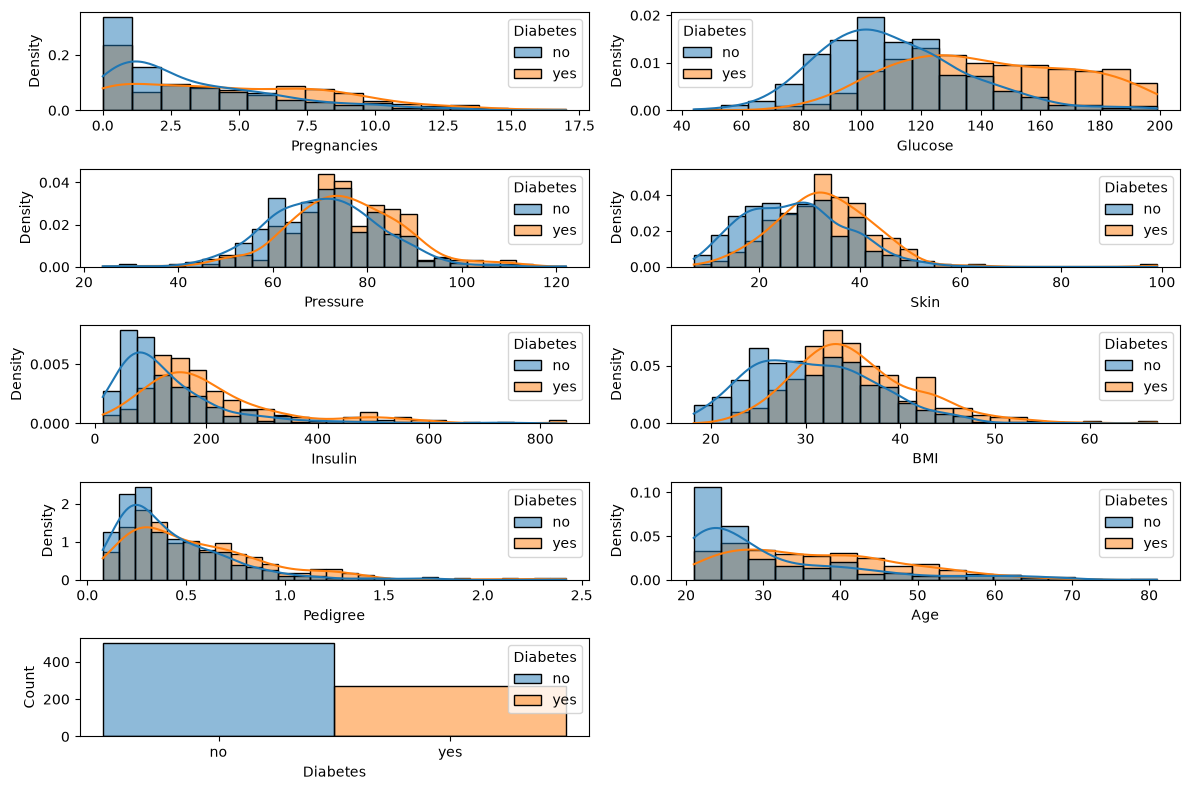

In [25]:
plot_marginal_dist(df, hue='Diabetes')

# Data analysis and descriptive statistics

Now that we are confident in our dataset, we can go further on and start to really analyze the data.

Remember we have already analyzed very roughly the dataset during the tutorial session (TD), where we considered the Pearson correlation matrix of features as a very rough measure for the statistical dependency between pair of variables:
<img src="fig/correlation.png" width=60%/>


We might ask given our prior knowledge about diabetes, for instance:
- What are the pairs of highly dependent variables, like expectedly `BMI` and `Skin`?
- What are the pairs of (almost) independent variables?
- What are the pairs of dependent variables whose relationship is not influenced by `Diabetes`?

We won't make any sophisticated statistical tests to validate our observations here (we should in theory).
We will only visualize empirical distributions and make some guess using *Seaborn*.

## Analysis of bivariate distributions

In this part we study the joint distribution of pairs of variables.

### Identification of strongly dependent pairs

**Question:**  
Draw the joint density of pairs of features using the *seaborn* `pairplot` function, using *kernel density estimate* (i.e option `kind='kde'`). Can you identify from these pairplots some very strongly dependent pairs? Try to interpret these observations given your knowledge about diabetes.

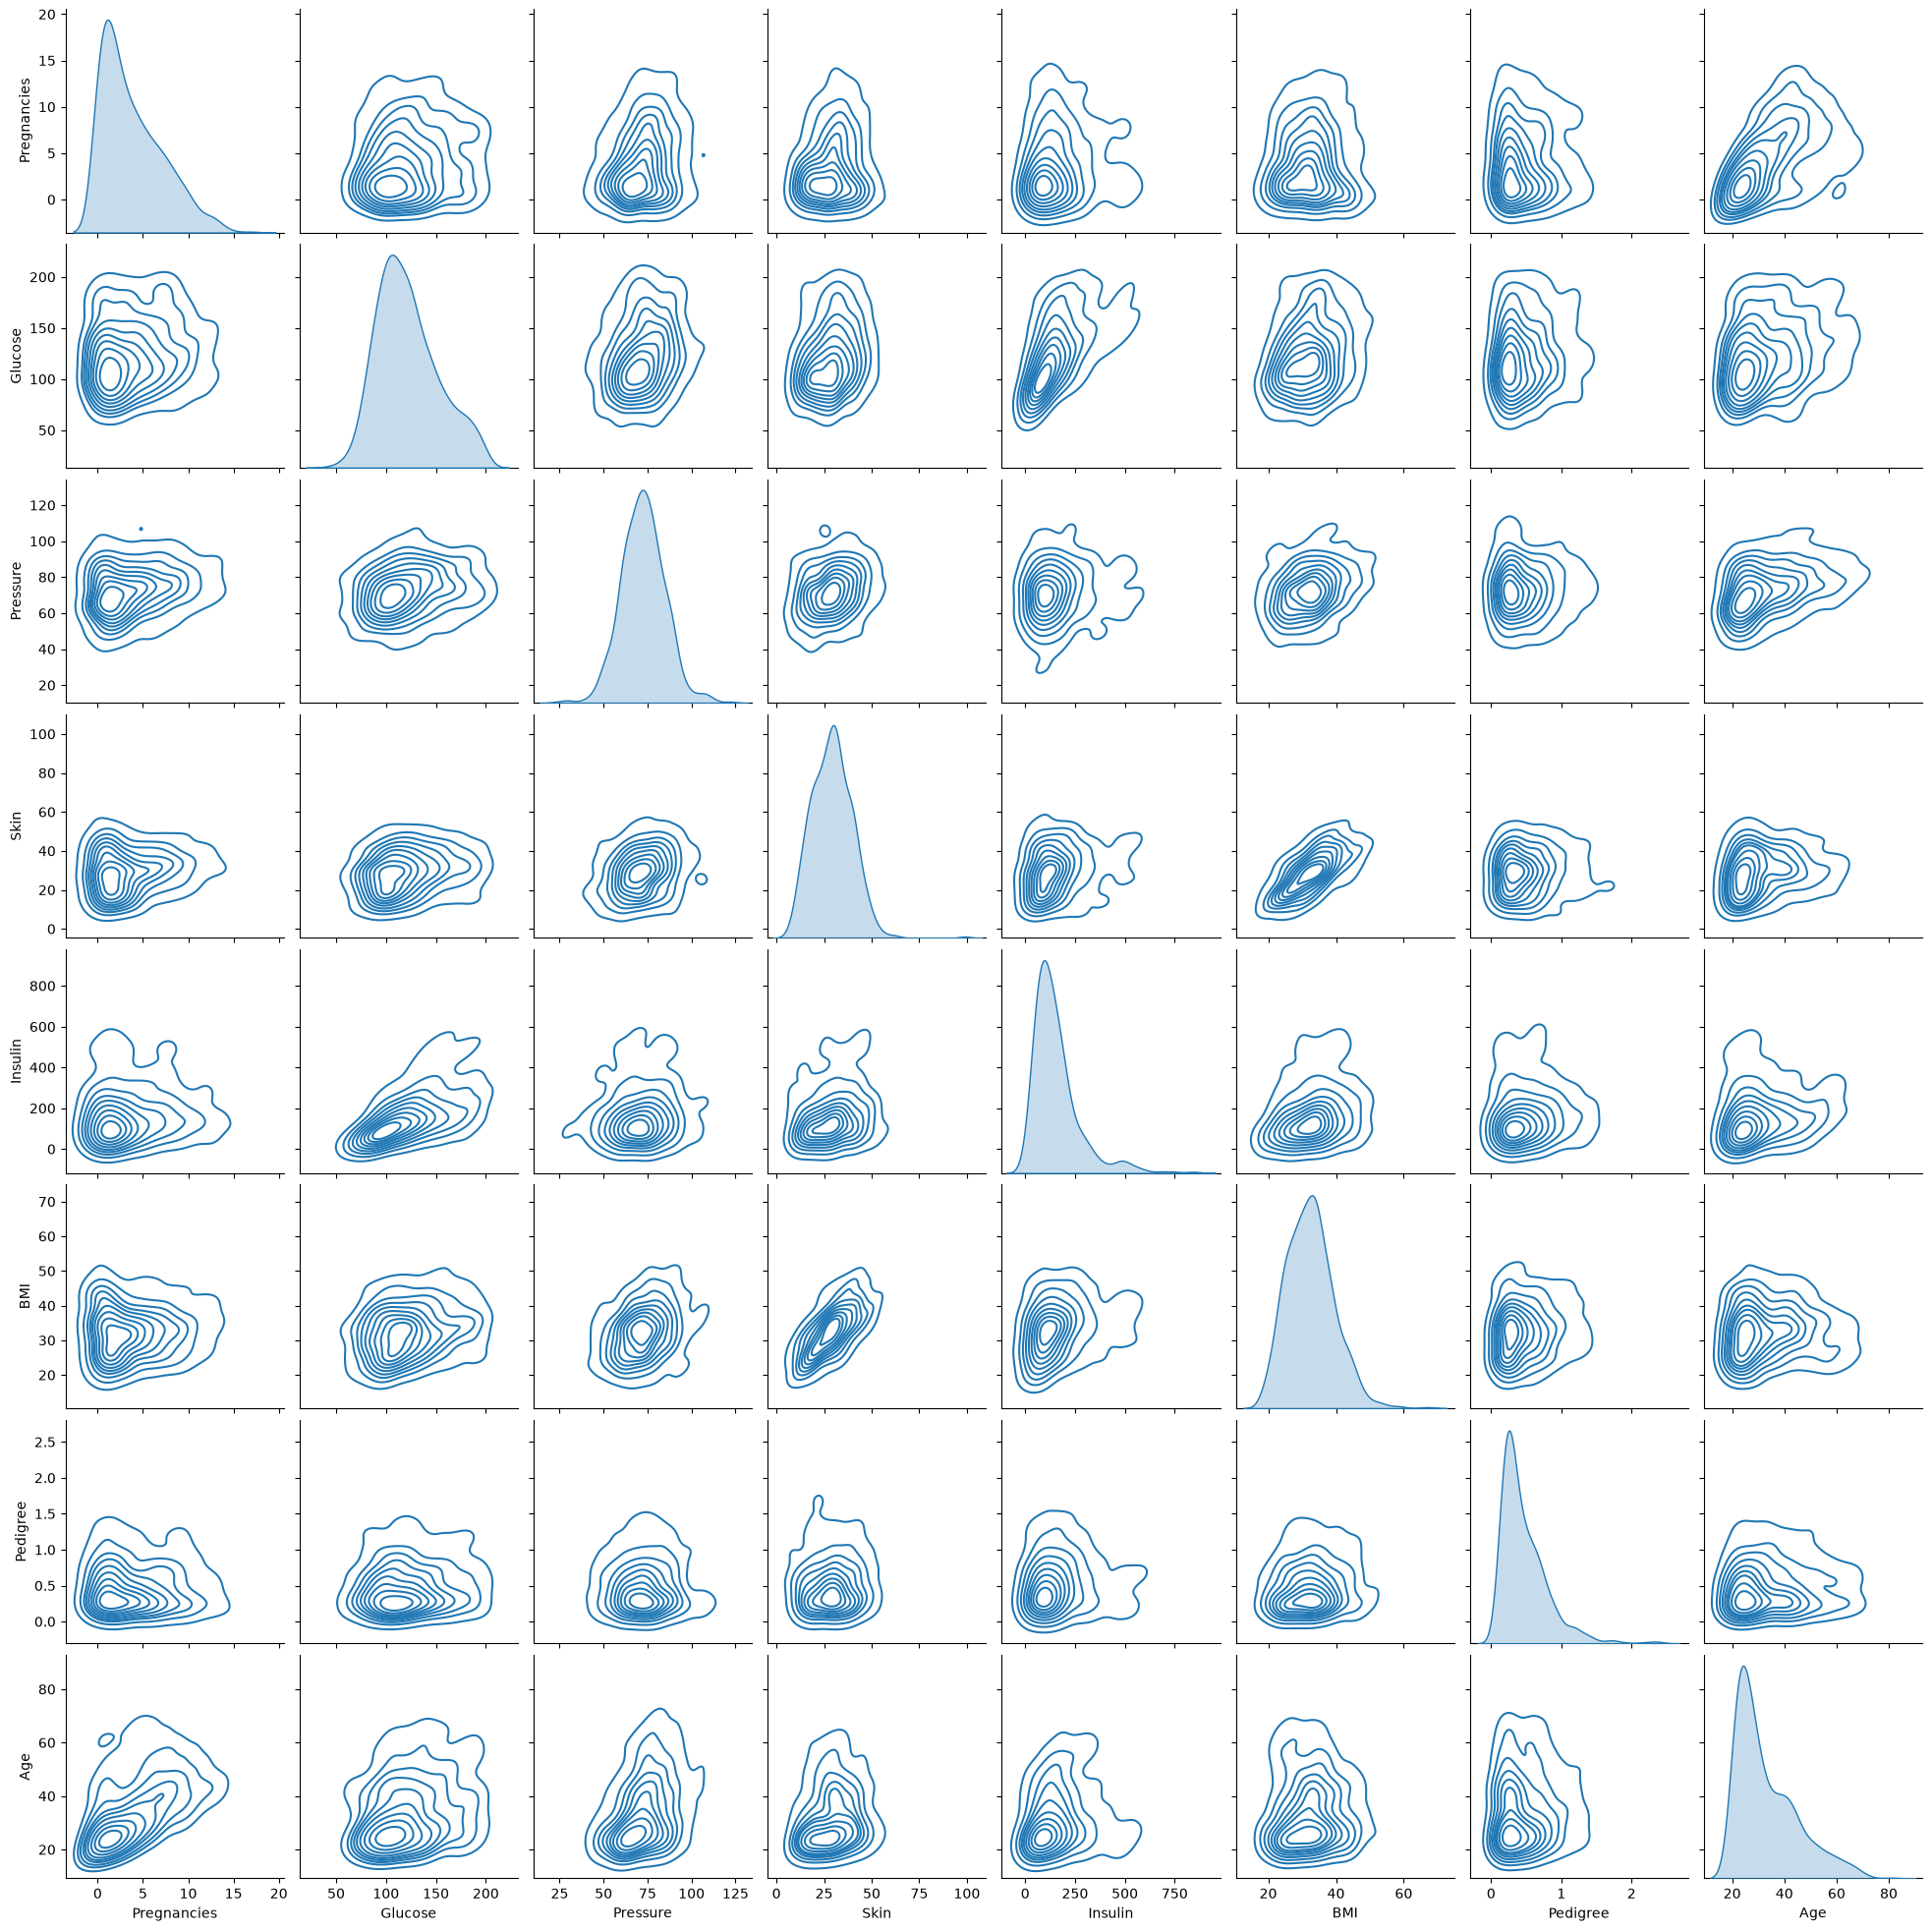

In [26]:
sns.pairplot(df, kind='kde')

### Identification of almost independent pairs

**Question:**  
Conversely can you deduce from the previous plots, pairs of mostly independent features? If not, can you imagine a better graphical plot, more adapted to identify variable independence ?

A more expressive represention to identify pairs of independent variables consists in computing the conditional density $p(X=x\,|\,Y=y) = \frac{p_{X,Y}(x,y)}{p_Y(y)}$ and to draw a 2D *contour plot* of this density, i.e. $(x,y) \mapsto p(X=x\,|\,Y=y)$, using KDE.
If the level lines are more are less vertical, $X$ and $Y$ can be considered as independent.

One issue with this approach, however, is to compute the conditional density $p(X=x\,|\,Y=y)$ only for points $(x,y)$ such that the estimated marginal density $p_Y(y) > \varepsilon$ is greater than some threshold, otherwise the conditional density estimation won't be statistically representative.

To save time, we provide the code to do so below in the module file `bivariate.py`.

**Question**:
Look at the two examples below that respectively draw the estimated joint density $p(\text{Glucose}, \text{Insulin})$ and the estimated conditional density $p(\text{Glucose}\,|\,\text{Insulin})$. Run the example. What can you conclude? How could we model the distribution $p(\text{Glucose}\,|\,\text{Insulin})$?

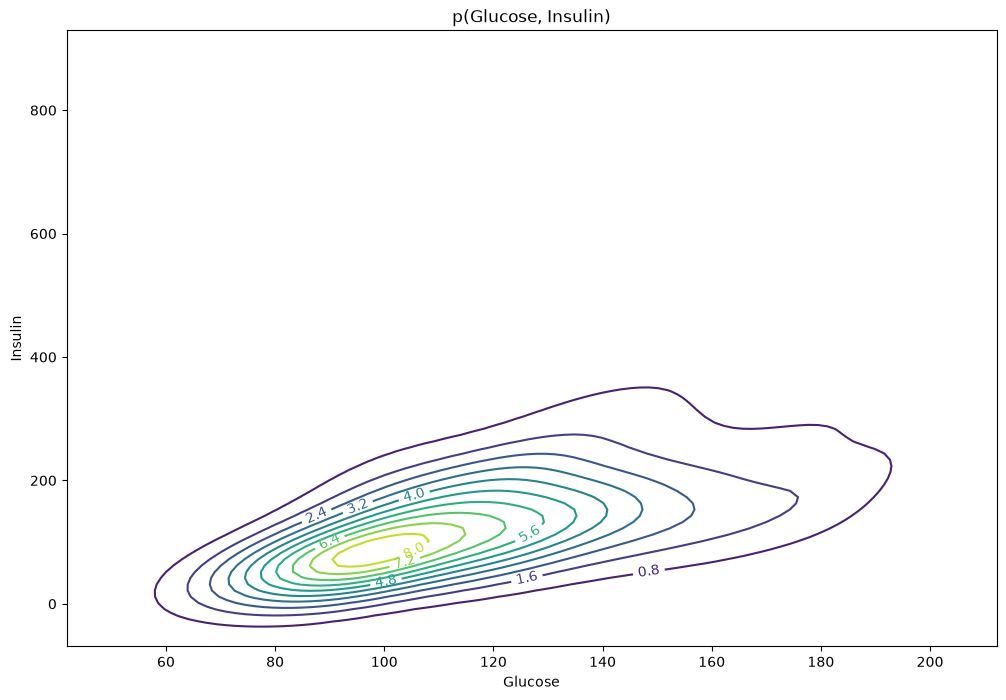

In [27]:
import bivariate

# Estimate the joint distribution of pair (Glucose, Insulin) using a kernel density estimate.
pXY= bivariate.get_bivariate_density(df, 'Glucose', 'Insulin')

# Plot the joint density as a 2D contour plot (i.e level z of point (x,y) is p(X=x, Y=y) )
pXY.plot()

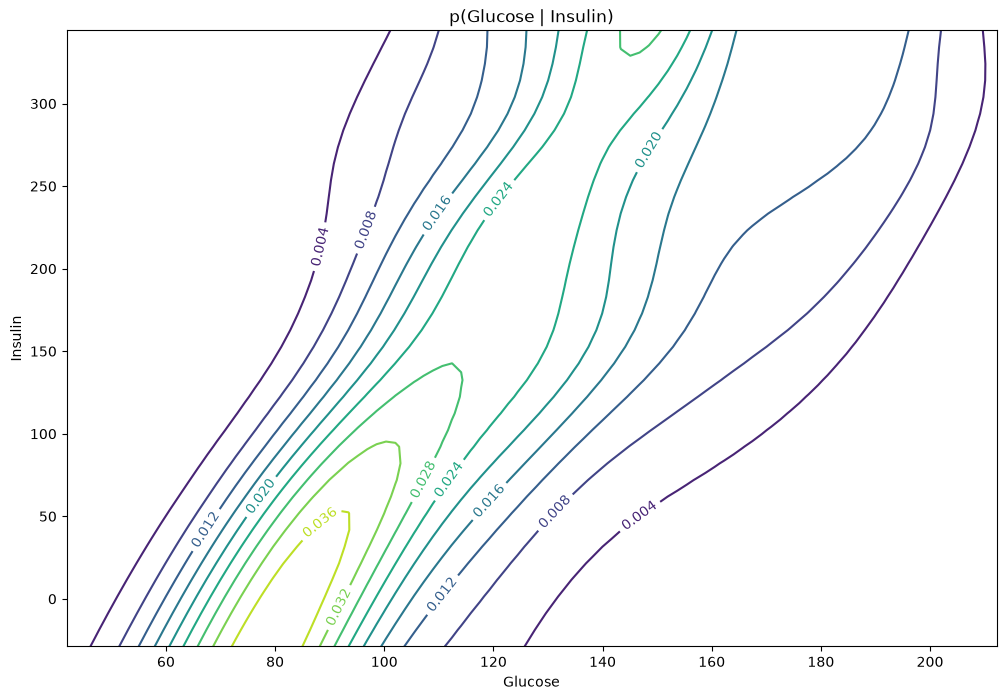

In [19]:
# Infer from the joint density pXY the conditional density PXgY of Glucose given Insulin from the joint distribution.
pXgY = pXY.conditional_density('Insulin')

# Plot the conditional density as a 2D contour plot (i.e level z of point (x,y) is p(X=x | Y=y) )
pXgY.plot()

On both graphs, we see that `Glucose` is highly dependent on `Insulin`. On the second graph, we see that the isodensity lines of the conditional density $p(\text{Glucose}|\text{Insulin})$ are parallel and oblique. This means the expected value of `Glucose` is roughly a linear function of `Insulin`. The dispersion along the x-axis and thus the standard deviation of `Glucose` increases slightly with `Insulin` but we can assume the standard deviation is constant as a first approach. A candidate model could thus be a linear model: $\text{Glucose} \sim \mathcal{N}(a \, \text{Insulin} + b, \sigma^2)$.

**Question:**  
For the sake of convenience, we introduce the next function `plot_conditional_density`. Use it for the pair `Pressure` and `Insulin`. What do you conclude?

In [20]:
def plot_conditional_density(df, V1, V2, colors=None):
    '''
    Plot the conditional density of V1 given V2
    '''
    pXY= bivariate.get_bivariate_density(df, V1, V2)
    pXgY = pXY.conditional_density(V2)
    pXgY.plot(colors=colors)

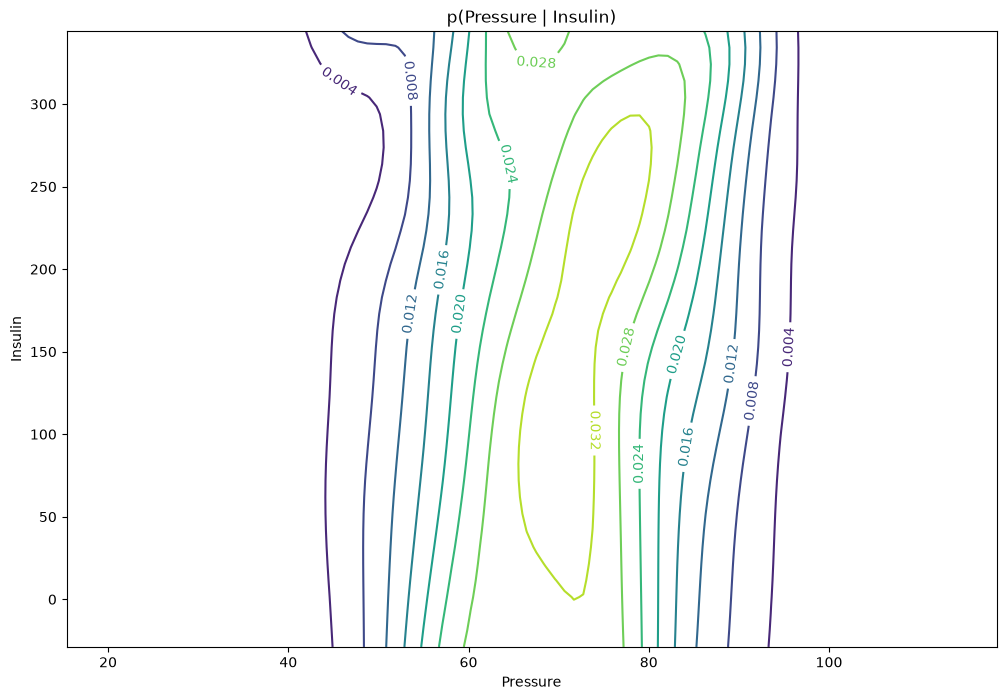

In [28]:
plot_conditional_density(df, 'Pressure', 'Insulin')

## Influence of diabetes on pairs of features

Now we want to analyze the dependency of pairs $(V_1,V_2)$ of variables with respect to diabetes.

More precisely, one would like to know whether `Diabetes` has some influence on the conditional distribution of $V_1$ given $V_2$ and conversely. 

### First case: no conditional influence of diabetes

Let's consider the pair `Skin`-`BMI`.
We can think the skin thickness `Skin` is purely a measure of the body mass index `BMI` (i.e. the fatter, the thicker the skin) and the diabetes has no influence on this relation even if we know obesity (and thus BMI) is one cause favouring diabetes.

Formally, this type of relation can be represented by the following belief network:
![case1](fig/BMI-Skin.png)

**Question:**  
How can you check graphically using function `plot_conditional_density()` whether this graph correctly describes the joint distribution of `BMI`, `Skin` and `Diabetes`?

**Question:**  
Look at the function `compare_conditional_densities()` below and use it to test whether the relation between skin thickness and BMI depends on diabetes. What can you conclude?

In [29]:
from matplotlib.lines import Line2D

def compare_conditional_densities(df, V1, V2):
    """
    Draws on the same plot the conditional densities p(V1|V2, Diabetes=yes) and p(V1|V2, Diabetes=no)
    """
    
    # Extract diabetic people to plot P(V1 | V2, Diabetes=yes) in red
    df_diabetes = df[df['Diabetes'] == 'yes']
    plot_conditional_density(df_diabetes, V1, V2, colors='r')
    
    # Extract non-diabetic people to plot P(V1 | V2, Diabetes=no) in blue
    df_no_diabetes = df[df['Diabetes'] == 'no']    
    plot_conditional_density(df_no_diabetes, V1, V2, colors='b')

    # Plot a custom legend
    custom_lines = [Line2D([0], [0], color='r', lw=4), Line2D([0], [0], color='b', lw=4)]
    plt.legend(custom_lines,['diabetes', 'no diabetes'])

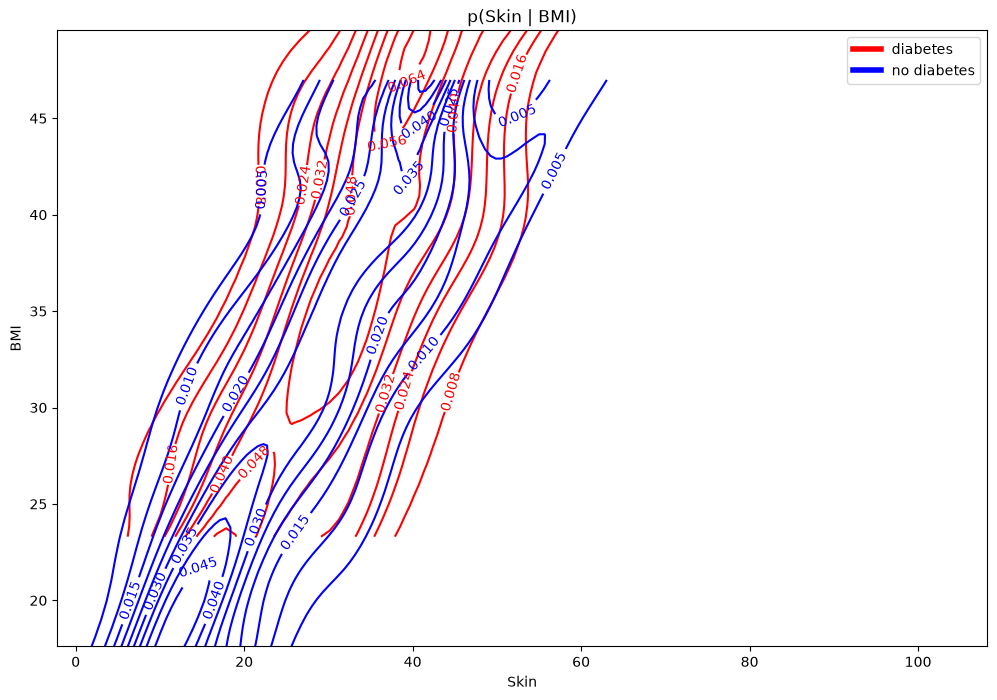

In [30]:
compare_conditional_densities(df, "Skin", "BMI")

### Second case: diabetes as a common cause

Now we look at a pair of variables for which diabetes is known to be a common causal factor.
For instance, we can guess that diabetes has some influence on the link between `Insulin` and `Glucose` since the disease disturbs the way insulin regulates the glucose rate in blood.

**Question:**  
First verify that both variables are dependent on `Diabetes` using `plot_marginal_dist`.

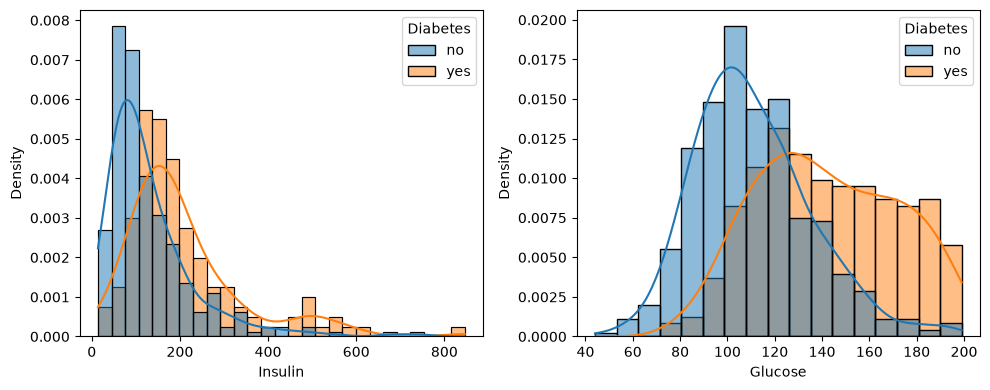

In [32]:
plt.rcParams['figure.figsize'] = [10, 4]
plot_marginal_dist(df, features=["Insulin", "Glucose"], hue='Diabetes')

However the causal dependence of insulin and glucose with diabetes can be expressed in three different ways, as summarized by the following graphs:<br>
![case2](fig/Insulin-Glucose.png)

**Question:**  
Compare the conditional densities to conclude which graph is correct.

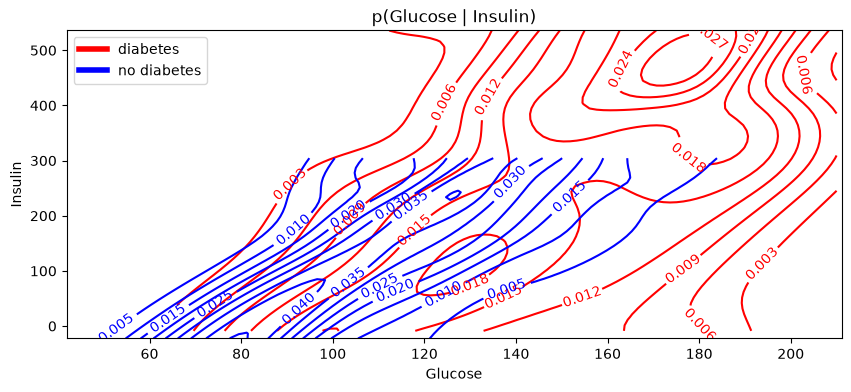

In [34]:
compare_conditional_densities(df, 'Glucose','Insulin')

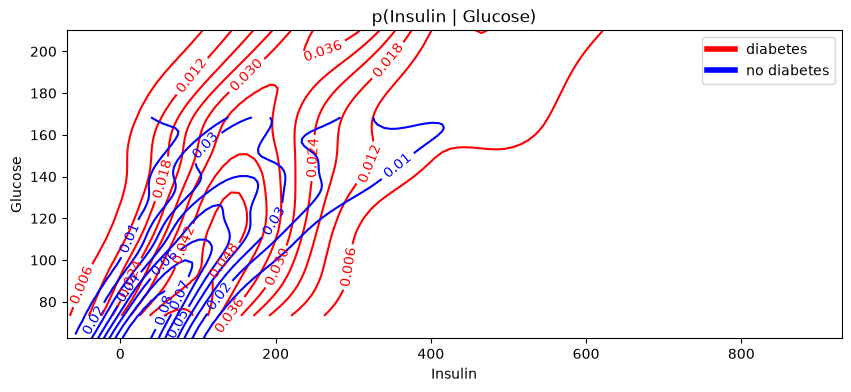

In [35]:
compare_conditional_densities(df, 'Insulin', 'Glucose')

### Third case: diabetes as a common consequence

Finally we study the case of two variables which are causal factors for diabetes, like `Pregnancies` and `BMI`.

**Question:**  
First check these two variables have some dependencies with diabetes.

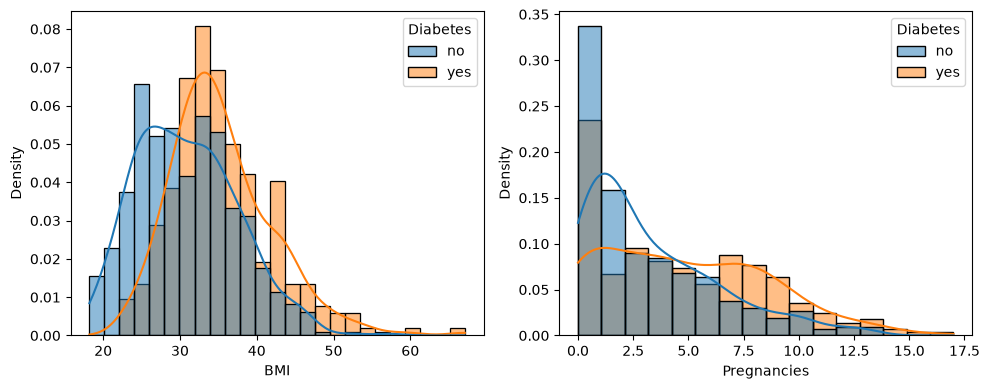

In [37]:
plt.rcParams['figure.figsize'] = [10, 4]
plot_marginal_dist(df, features=['BMI','Pregnancies'], hue='Diabetes')

There is no simple causal dependency between `Pregnancies` and `BMI` so we decide an arbitrary orientation between both variables. We then consider two hypothesis represented by the next graphs:
![case3](fig/BMI-Pregnancies.png)

**Question:**  
Again, compare the conditional densities to conclude which graph is correct.

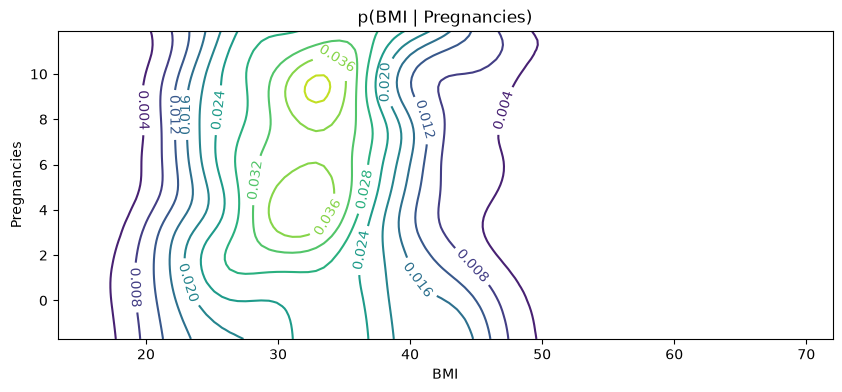

In [38]:
plot_conditional_density(df, 'BMI', 'Pregnancies')

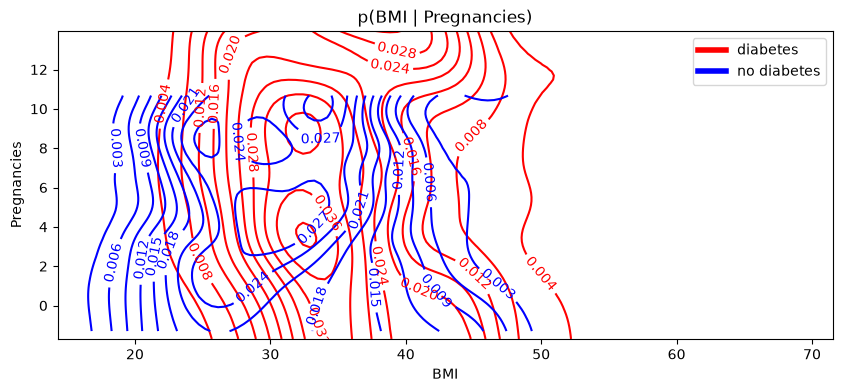

In [39]:
compare_conditional_densities(df, 'BMI', 'Pregnancies')

 # Diabetes prediction
 
We are now interested in predicting diabetes from the observation of descriptive variables.
To choose a suitable predictive model, we first look at the shape of feature distributions for each class.

**Question:**  
Use the `hue` option of *Searborn*'s `pairplot` to visualize per-class distributions of pairs of variables.

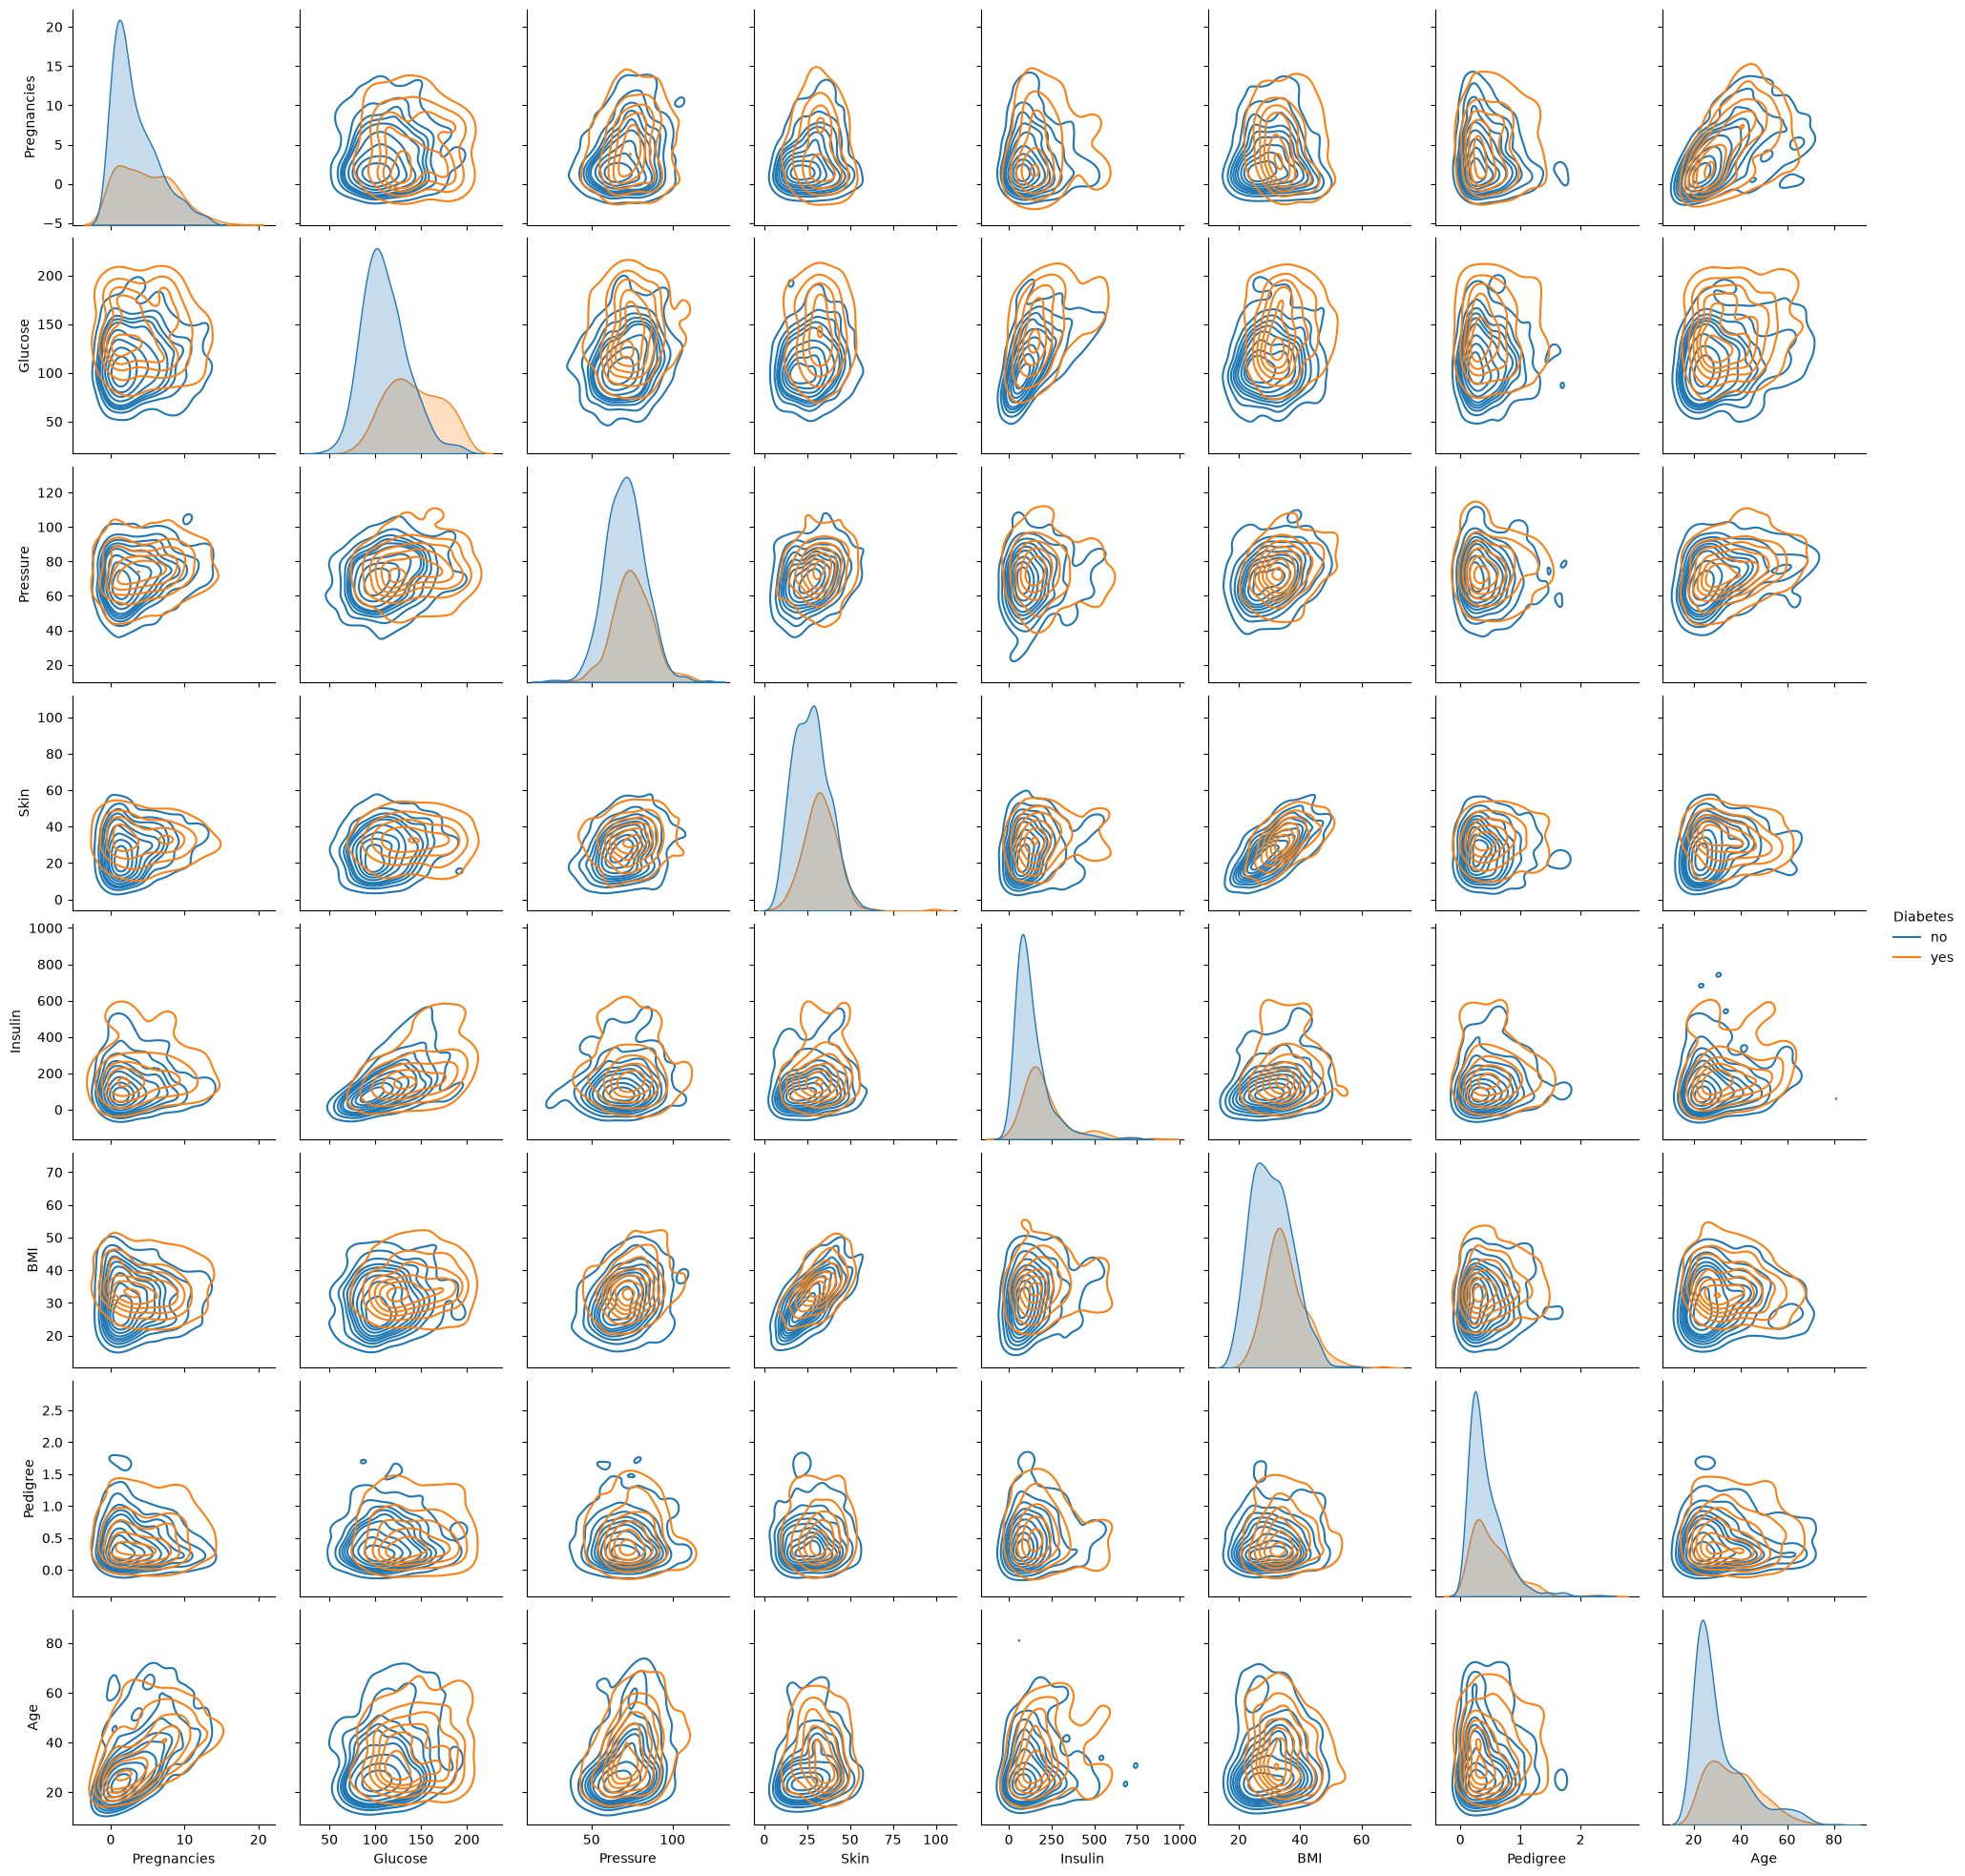

In [40]:
sns.pairplot(df, kind='kde', hue='Diabetes')

**Question:**  
Considering marginal distributions $P(X\,|\,Y)$ of each feature $X$ given the class $Y$ visible on the grid diagonal, what parametric distribution could be a rough approximation of these distributions? Does it generalize rougly when considering pairwise joint distributions $P(X_1,X_2 \,|\, Y)$? Propose a classification model (*tip: seen during the lectures*) that corresponds to this approximation.

**Question:**  
What do you think about the level of difficulty to predict diabetes? What can you say qualitatively about levels of aleatoric and epistemic uncertainties?

## Gaussian Discriminant Analysis

### Dealing with missing values: data imputation

**Question:**  
Evalue QDA on our problem using the class `QuadraticDiscriminantAnalysis` of *scikit-learn* (and our `ScoreBoard` class). What's the problem?

In [41]:
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

# Don't forget to extract the features again, this time with the missing features
X = df.loc[:, features]

qda = QuadraticDiscriminantAnalysis()

try:
    scores.test('QDA', qda, X, y)
except ValueError as e:
    print(e)
scores

Input X contains NaN.
QuadraticDiscriminantAnalysis does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values


,classifier,acc,auc,logL
0,NaiveBayes,0.756494,0.815991,-0.620058
1,LogReg,0.773479,0.829419,-0.484010
2,RandomForest,0.768233,0.828407,-0.481698


As you can see many classifiers do not support NAN values.
A workaround consists in **imputing missing values**, i.e replacing NAN with some plausible values.
*Scikit-learn* proposes readily available methods to do so, for instance, replacing the missing value by the mean or median of the corresponding feature, or training a model to predict the feature from the other observable features, etc.

**Question:**  
Let's do something simple here and build an imputed numpy array `X_imputed` using *Scikit-learn* class `SimpleImputer` following the examples provided on the [link](https://scikit-learn.org/stable/modules/impute.html). Then test again QDA.

In [42]:
from sklearn.impute import SimpleImputer

def impute_missing_values(df, features=None):
    if features is None:
        features = list(df.columns)
        features.remove('Diabetes')

    X = df.loc[:, features]
    
    imputer = SimpleImputer(missing_values=np.nan, strategy='median')
    imputer.fit(X)
    return imputer.transform(X)

In [43]:
X_imputed = impute_missing_values(df)
scores.test('QDA', qda, X_imputed, y)
scores

,classifier,acc,auc,logL
0,NaiveBayes,0.756494,0.815991,-0.620058
1,LogReg,0.773479,0.829419,-0.484010
2,RandomForest,0.768233,0.828407,-0.481698
3,QDA,0.740909,0.808627,-0.649725


### Data transformation

One limitation of QDA is that the input features are assumed to be normally distributed.
In our case, this assumption is obviously wrong since all features are positive numbers, either real numbers or integers. This explains why the loglikelihood is worse as the MVN do not match very well the observed empirical distributions.

**Question:**  
What transformation could be applied to input features so that once transformed, features are more likely to follow normal distributions.  

To save you time, the following code transforms the input dataframe `df` into a transformed `log_df` according to provided the transformation function provided for each feature. 

**Question:**  
Run the code. Then verify that the features of `log_df` have marginal and pairwise distributions closer to normal distributions.

In [44]:
def transform_features(df, transforms, prefix=''):  
    '''
    Returns a dataframe resulting from the application of transformations to every column of some input dataframe
    - df: input dataframe
    - transforms: dictionary mapping feature names to transformation functions
      Missing features are left unmodified.
    - prefix: optional prefix to add to transformed feature names
    '''
    
    # Make a copy the original dataframe
    df2 = df.copy()
    
    # Transform features
    for feature in df.columns:
        if feature in transforms:
            transformation = transforms[feature]
            del df2[feature]
            if transformation is not None:
                df2[prefix + feature] = transformation(df[feature])
    return df2

In [45]:
transforms = {
    'Age': np.log,
    'BMI': np.log,
    'Insulin': np.log,
    'Glucose': np.log,
    'Pedigree': np.log,
    'Pregnancies': lambda x : np.log(x + 1),
    'Pressure': np.log,
    'Skin': np.log
}

log_df = transform_features(df, transforms, 'log')
log_df.head()

,Diabetes,logPregnancies,logGlucose,logPressure,logSkin,logInsulin,logBMI,logPedigree,logAge
0,yes,1.945910,4.997212,4.276666,3.555348,NaN,3.514526,-0.466809,3.912023
1,no,0.693147,4.442651,4.189655,3.367296,NaN,3.280911,-1.046969,3.433987
2,yes,2.197225,5.209486,4.158883,NaN,NaN,3.148453,-0.397497,3.465736
3,no,0.693147,4.488636,4.189655,3.135494,4.543295,3.335770,-1.789761,3.044522
4,yes,0.000000,4.919981,3.688879,3.555348,5.123964,3.763523,0.827678,3.496508


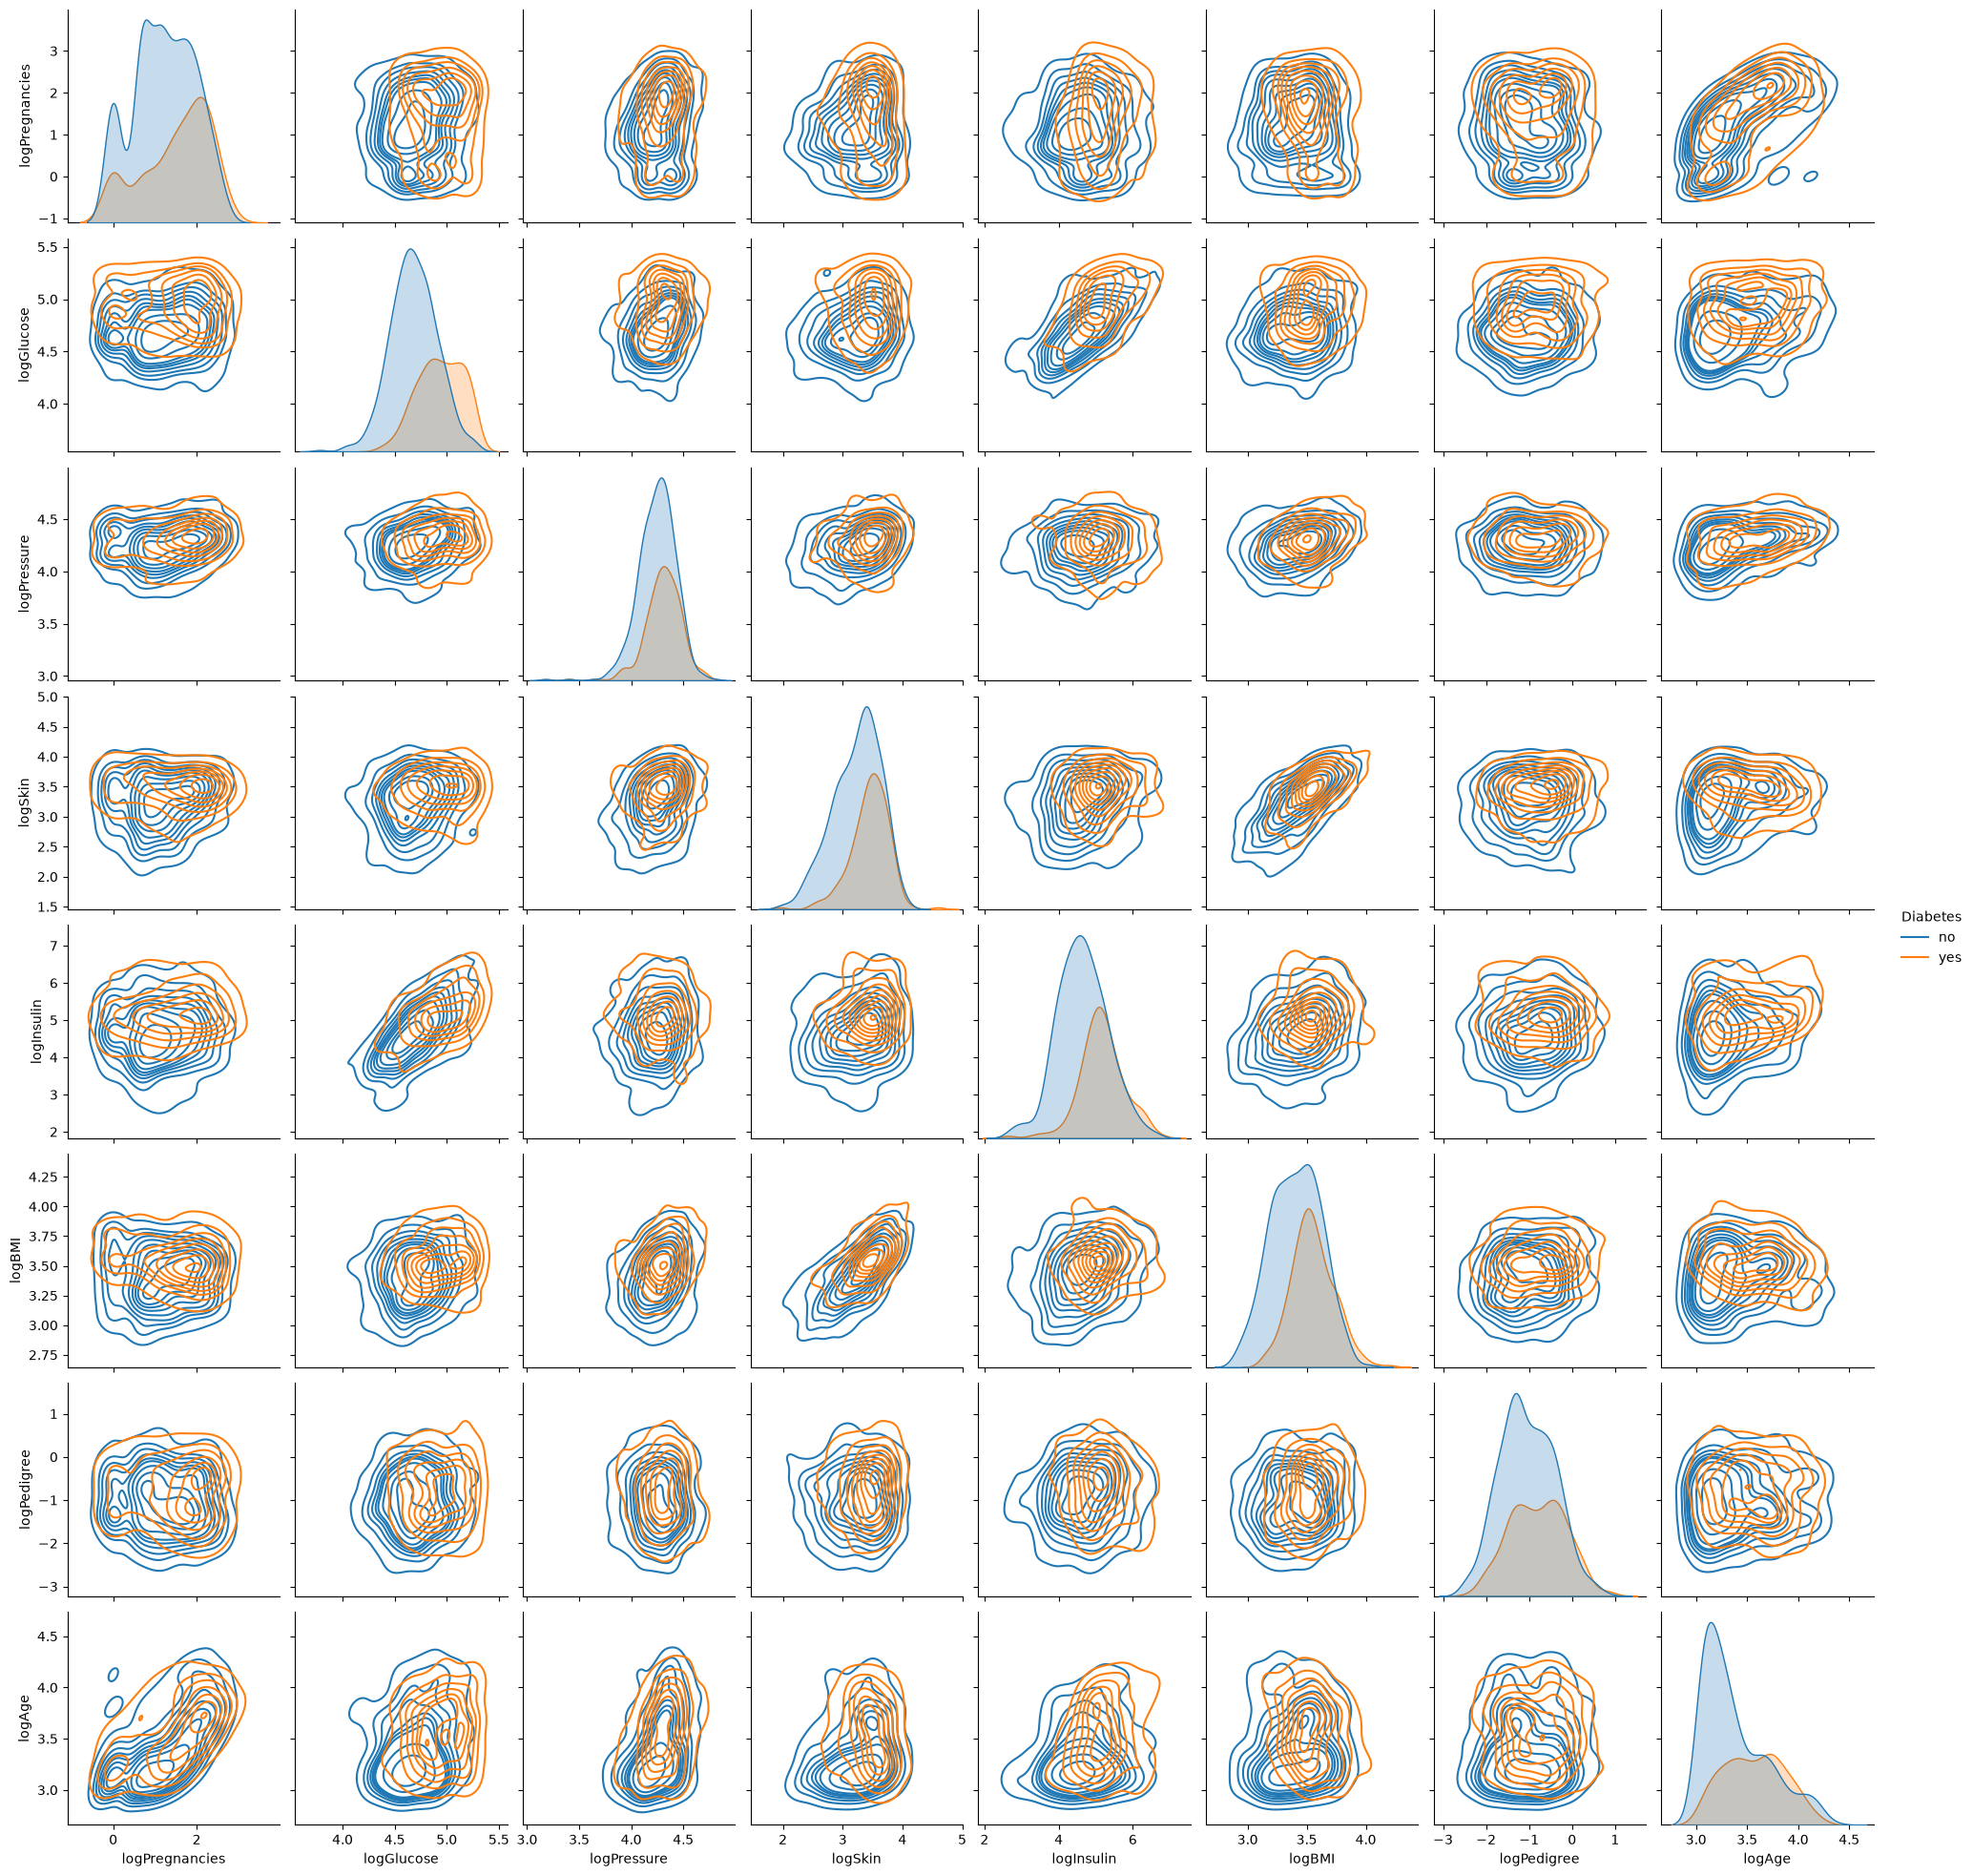

In [46]:
sns.pairplot(log_df, kind='kde', hue='Diabetes')

**Question:**  
Apply QDA to the transformed dataframe (don't forget to impute missing values on this new dataset). What do you observe in term of performance? Is is consistent?

In [47]:
X_imputed = impute_missing_values(log_df)
scores.test('QDA+log', qda, X_imputed, y)
scores

,classifier,acc,auc,logL
0,NaiveBayes,0.756494,0.815991,-0.620058
1,LogReg,0.773479,0.829419,-0.484010
2,RandomForest,0.768233,0.828407,-0.481698
3,QDA,0.740909,0.808627,-0.649725
4,QDA+log,0.760407,0.825573,-0.505953


**Question:**  
Apply LDA (Linear Discriminant Analysis) instead of QDA to the transformed dataset, using the *Scikit-learn*'s `LinearDiscriminantAnalysis` class. Observe the performance. What can you conclude?

In [48]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
lda = LinearDiscriminantAnalysis()
scores.test('LDA+log', lda, X_imputed, y)
scores

,classifier,acc,auc,logL
0,NaiveBayes,0.756494,0.815991,-0.620058
1,LogReg,0.773479,0.829419,-0.484010
2,RandomForest,0.768233,0.828407,-0.481698
3,QDA,0.740909,0.808627,-0.649725
4,QDA+log,0.760407,0.825573,-0.505953
5,LDA+log,0.760441,0.841490,-0.468504


**Question:**  
Finally test the *shrinkage* LDA (i.e a form of regularization of the LDA covariance matrix if LDA is still over-parameterized) by passing the options `solver="lsqr"` and `shrinkage="auto"` to the constructor of `LinearDiscriminantAnalysis`. What do you conclude from the results?

In [49]:
shrunk_lda = LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")
scores.test('Shrunk-LDA+log', shrunk_lda, X_imputed, y)
scores

,classifier,acc,auc,logL
0,NaiveBayes,0.756494,0.815991,-0.620058
1,LogReg,0.773479,0.829419,-0.484010
2,RandomForest,0.768233,0.828407,-0.481698
3,QDA,0.740909,0.808627,-0.649725
4,QDA+log,0.760407,0.825573,-0.505953
5,LDA+log,0.760441,0.841490,-0.468504
6,Shrunk-LDA+log,0.763038,0.841815,-0.468439


# Conclusion: why should we bother about the method?

In the end, we observe rather small differences of performance between methods.
So let's finish this labwork by some analysis of the reasons why QDA/LDA is interesting here.

**Question:**  
What is the interest of QDA/LDA compared to models such as logistic regression or random forests?

**Question:**  
What is the interest of QDA/LDA compared to Naive Bayes?